# Wikipedia Page Ranking Using the PageRank Algorithm

## Project Overview
This project analyzes the link structure of Wikipedia pages using the PageRank algorithm. The dataset contains Wikipedia page metadata and directed hyperlinks between pages.

## Dataset
- **Dataset:** Wikipedia Link Graph Dataset – 100K Pages
- **Source:** Kaggle
- **Pages:** 100,000
- **Original links:** 28,855,738

## Tools and Libraries
- Python
- Google Colab
- Pandas
- NetworkX
- Matplotlib
- Google Drive

## Workflow
1. Dataset inspection
2. Data preprocessing and graph construction
3. Graph statistics
4. PageRank calculation
5. Ranking and visualization
6. Evaluation and conclusions

In [ ]:
import os
import json
import pickle
import zipfile
from pathlib import Path

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import os
import zipfile
from pathlib import Path

zip_path = "/content/wikipedia_pagerank_prepared_data.zip"
output_dir = Path("/content/wikipedia_pagerank_prepared_data")

if not output_dir.exists() or not any(output_dir.iterdir()):
    output_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(output_dir)

print("Prepared dataset extracted!")

for file in output_dir.rglob("*"):
    if file.is_file():
        print(file.name, round(file.stat().st_size / (1024**2), 2), "MB")

Prepared dataset extracted!
graph_statistics.json 0.0 MB
wikipedia_pages_metadata.csv 2.44 MB
wikipedia_graph_100k.pkl 221.28 MB


In [ ]:
graph_path = output_dir / "wikipedia_graph_100k.pkl"
metadata_path = output_dir / "wikipedia_pages_metadata.csv"
stats_path = output_dir / "graph_statistics.json"

with open(graph_path, "rb") as f:
    G_100k = pickle.load(f)

pages = pd.read_csv(metadata_path)

with open(stats_path, "r") as f:
    stats = json.load(f)

print("Graph and metadata loaded successfully!")
print("Metadata shape:", pages.shape)
print("Graph nodes:", G_100k.number_of_nodes())
print("Graph edges:", G_100k.number_of_edges())

Graph and metadata loaded successfully!
Metadata shape: (100000, 2)
Graph nodes: 100000
Graph edges: 8577044


In [ ]:
print(json.dumps(stats, indent=4))

{
    "dataset_pages": 100000,
    "graph_nodes": 100000,
    "graph_edges": 8577044,
    "self_loops": 4326,
    "pages_with_no_outgoing_links": 204
}


In [ ]:
print("Directed graph:", G_100k.is_directed())
print("Nodes:", G_100k.number_of_nodes())
print("Edges:", G_100k.number_of_edges())
print("Self-loops:", nx.number_of_selfloops(G_100k))

zero_outdegree = sum(
    1 for _, d in G_100k.out_degree() if d == 0
)

zero_indegree = sum(
    1 for _, d in G_100k.in_degree() if d == 0
)

print("Pages with no outgoing links:", zero_outdegree)
print("Pages with no incoming links:", zero_indegree)

assert G_100k.number_of_nodes() == 100000
assert G_100k.is_directed()

Directed graph: True
Nodes: 100000
Edges: 8577044
Self-loops: 4326
Pages with no outgoing links: 204
Pages with no incoming links: 0


In [ ]:
in_degrees = dict(G_100k.in_degree())
out_degrees = dict(G_100k.out_degree())

graph_summary = {
    "nodes": G_100k.number_of_nodes(),
    "edges": G_100k.number_of_edges(),
    "self_loops": nx.number_of_selfloops(G_100k),
    "average_in_degree": sum(in_degrees.values()) / len(in_degrees),
    "average_out_degree": sum(out_degrees.values()) / len(out_degrees),
    "maximum_in_degree": max(in_degrees.values()),
    "maximum_out_degree": max(out_degrees.values()),
    "zero_in_degree_pages": zero_indegree,
    "zero_out_degree_pages": zero_outdegree
}

print(pd.Series(graph_summary).to_string())

nodes                    1.000000e+05
edges                    8.577044e+06
self_loops               4.326000e+03
average_in_degree        8.577044e+01
average_out_degree       8.577044e+01
maximum_in_degree        5.153500e+04
maximum_out_degree       1.765000e+03
zero_in_degree_pages     0.000000e+00
zero_out_degree_pages    2.040000e+02


In [ ]:
top_in_degree = sorted(
    in_degrees.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]

top_pages = pd.DataFrame(
    top_in_degree,
    columns=["title", "in_degree"]
)

display(top_pages)

,title,in_degree
0,ISBN (identifier),51535
1,Doi (identifier),31462
2,Wayback Machine,24295
3,ISSN (identifier),23311
4,S2CID (identifier),17820
5,Bibcode (identifier),12397
6,OCLC (identifier),11888
7,JSTOR (identifier),11254
8,PMID (identifier),9912
9,Time zone,9293


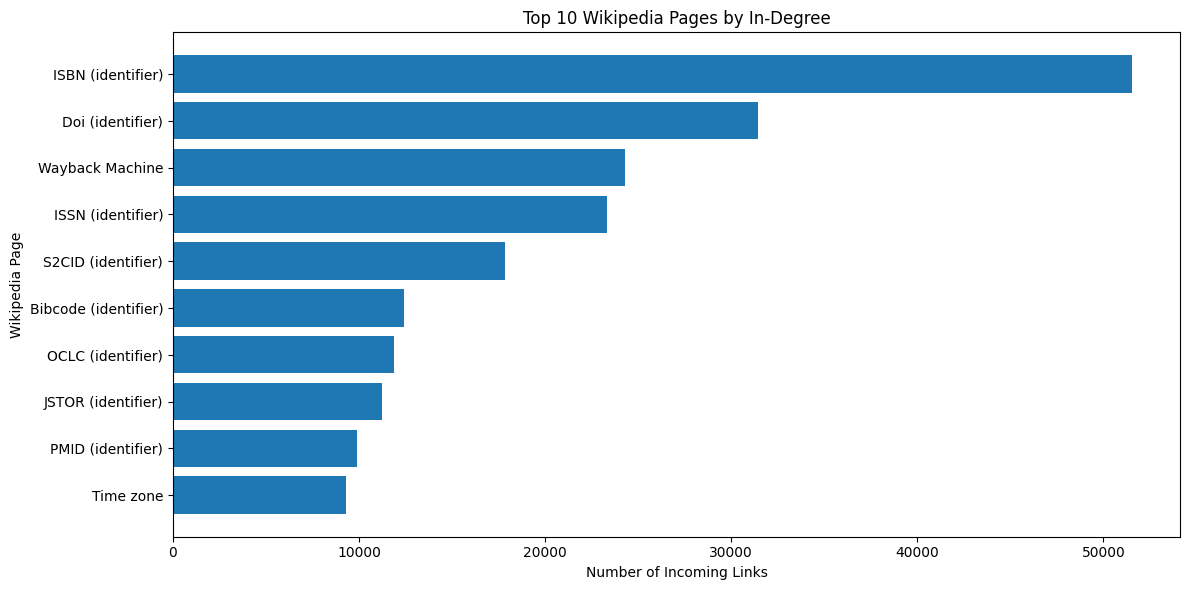

In [ ]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_pages["title"][::-1],
    top_pages["in_degree"][::-1]
)

plt.xlabel("Number of Incoming Links")
plt.ylabel("Wikipedia Page")
plt.title("Top 10 Wikipedia Pages by In-Degree")
plt.tight_layout()
plt.show()

In [ ]:
results_dir = Path("/content/graph_analysis_results")
results_dir.mkdir(exist_ok=True)

# Save top 10 pages by in-degree
top_pages.to_csv(
    results_dir / "top_10_in_degree.csv",
    index=False
)

# Save graph statistics
with open(results_dir / "graph_summary.json", "w") as f:
    json.dump(graph_summary, f, indent=4)

print("Graph analysis outputs saved successfully!")

print("Files saved:")
for file in results_dir.iterdir():
    print(file.name)

Graph analysis outputs saved successfully!
Files saved:
graph_summary.json
top_10_in_degree.csv


## PageRank Implementation

PageRank measures the importance of a page based on the links pointing to it and the importance of the pages providing those links. We use a damping factor of 0.85 and calculate scores for all 100,000 pages.

In [ ]:

# This version retains the dataset's self-loops.
import time

damping_factor = 0.85
tolerance = 1e-6
max_iterations = 100

start_time = time.time()

pagerank_scores = nx.pagerank(
    G_100k,
    alpha=damping_factor,
    max_iter=max_iterations,
    tol=tolerance
)

elapsed_time = time.time() - start_time

print("PageRank calculated successfully!")
print("Pages ranked:", len(pagerank_scores))
print("Damping factor:", damping_factor)
print("Convergence tolerance:", tolerance)
print("Execution time (seconds):", round(elapsed_time, 2))
print("Sum of PageRank scores:", sum(pagerank_scores.values()))

PageRank calculated successfully!
Pages ranked: 100000
Damping factor: 0.85
Convergence tolerance: 1e-06
Execution time (seconds): 21.18
Sum of PageRank scores: 0.9999999999999997


In [ ]:

# Check that the existing results are available
if "pagerank_scores" not in globals():
    raise NameError(
        "pagerank_scores is missing. Run Cell 10 first."
    )

if "pages" not in globals():
    raise NameError(
        "pages is missing. Run Cell 3 first."
    )

print("Number of PageRank scores:", len(pagerank_scores))
print("\nMetadata columns:", pages.columns.tolist())

# Sort all pages by PageRank score
pagerank_ranking = pd.DataFrame(
    pagerank_scores.items(),
    columns=["title", "pagerank_score"]
)

pagerank_ranking = pagerank_ranking.sort_values(
    by="pagerank_score",
    ascending=False
).reset_index(drop=True)

# Add rank numbers starting from 1
pagerank_ranking.insert(
    0, "pagerank_rank",
    range(1, len(pagerank_ranking) + 1)
)

print("\nTotal ranked pages:", len(pagerank_ranking))
print("\nTop 20 Wikipedia pages by PageRank:")

display(pagerank_ranking.head(20))


Number of PageRank scores: 100000

Metadata columns: ['id', 'title']

Total ranked pages: 100000

Top 20 Wikipedia pages by PageRank:


,pagerank_rank,title,pagerank_score
0,1,ISBN (identifier),0.010151
1,2,Doi (identifier),0.006186
2,3,ISSN (identifier),0.005008
3,4,Wayback Machine,0.004851
4,5,S2CID (identifier),0.003310
5,6,OCLC (identifier),0.002455
6,7,Bibcode (identifier),0.002299
7,8,PMID (identifier),0.002266
8,9,JSTOR (identifier),0.001883
9,10,United States,0.001768


In [ ]:
results_dir = Path("/content/graph_analysis_results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save the full ranking of 100,000 pages
pagerank_ranking.to_csv(
    results_dir / "pagerank_ranking_100k.csv",
    index=False
)

# Save the top 10 pages separately
top_10_pagerank = pagerank_ranking.head(10).copy()

top_10_pagerank.to_csv(
    results_dir / "top_10_pagerank.csv",
    index=False
)

print("PageRank results saved successfully!")

print("\nSaved files:")
print(results_dir / "pagerank_ranking_100k.csv")
print(results_dir / "top_10_pagerank.csv")

print("\nTop 10 PageRank pages:")
display(top_10_pagerank)

PageRank results saved successfully!

Saved files:
/content/graph_analysis_results/pagerank_ranking_100k.csv
/content/graph_analysis_results/top_10_pagerank.csv

Top 10 PageRank pages:


,pagerank_rank,title,pagerank_score
0,1,ISBN (identifier),0.010151
1,2,Doi (identifier),0.006186
2,3,ISSN (identifier),0.005008
3,4,Wayback Machine,0.004851
4,5,S2CID (identifier),0.003310
5,6,OCLC (identifier),0.002455
6,7,Bibcode (identifier),0.002299
7,8,PMID (identifier),0.002266
8,9,JSTOR (identifier),0.001883
9,10,United States,0.001768


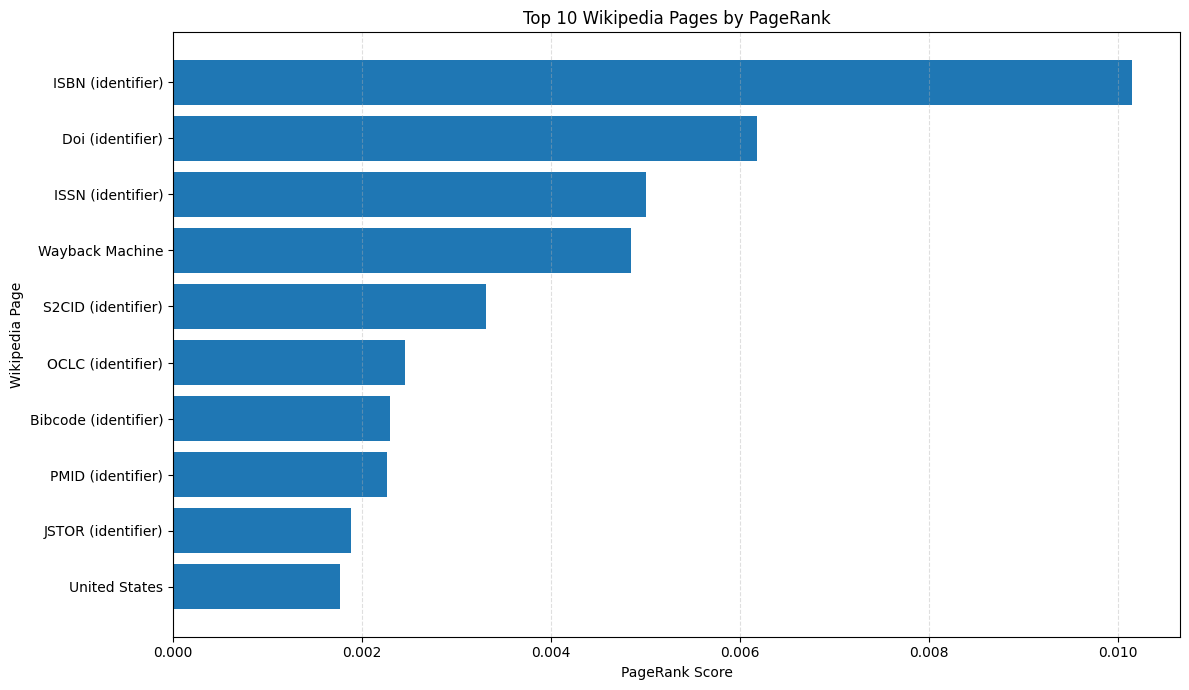

Chart saved to: /content/graph_analysis_results/top_10_pagerank.png


In [ ]:


import textwrap

# Check that Cell 12 has run
if "top_10_pagerank" not in globals():
    raise NameError("Run Cells 11 and 12 first.")

plot_data = top_10_pagerank.sort_values(
    "pagerank_score", ascending=True
).copy()

# Wrap long titles for readability
labels = [
    "\n".join(textwrap.wrap(str(title), width=28))
    for title in plot_data["title"]
]

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(labels, plot_data["pagerank_score"])

ax.set_xlabel("PageRank Score")
ax.set_ylabel("Wikipedia Page")
ax.set_title("Top 10 Wikipedia Pages by PageRank")
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save the figure
plt.savefig(
    results_dir / "top_10_pagerank.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", results_dir / "top_10_pagerank.png")


In [ ]:

# Compare PageRank and in-degree rankings

from scipy.stats import spearmanr

# Build a complete in-degree ranking from existing values
in_degree_ranking = pd.DataFrame(
    in_degrees.items(),
    columns=["title", "in_degree"]
)

in_degree_ranking["in_degree_rank"] = (
    in_degree_ranking["in_degree"]
    .rank(method="average", ascending=False)
)

# Merge the two rankings using their graph node identifiers
comparison = in_degree_ranking.merge(
    pagerank_ranking[["title", "pagerank_rank", "pagerank_score"]],
    on="title",
    how="inner",
    validate="one_to_one"
)

print("Pages matched across both rankings:", len(comparison))

# Top 10 from each method
top10_indegree_titles = set(
    in_degree_ranking.nsmallest(10, "in_degree_rank")["title"]
)

top10_pagerank_titles = set(
    pagerank_ranking.head(10)["title"]
)

overlap = top10_indegree_titles & top10_pagerank_titles

print("\nTop 10 overlap:", len(overlap), "pages")
print("Pages in both top 10 lists:", sorted(overlap))

print("\nPages in the top 10 of either method:")
top10_union = comparison[
    comparison["title"].isin(
        top10_indegree_titles | top10_pagerank_titles
    )
].sort_values("pagerank_rank")

display(top10_union[
    ["title", "in_degree", "in_degree_rank",
     "pagerank_score", "pagerank_rank"]
])

# Spearman correlation between in-degree and PageRank scores
correlation, p_value = spearmanr(
    comparison["in_degree"],
    comparison["pagerank_score"]
)

print("\nSpearman rank correlation:", round(correlation, 4))
print("P-value:", p_value)

# Save comparison outputs
comparison.to_csv(
    results_dir / "indegree_pagerank_comparison_100k.csv",
    index=False
)

top10_union.to_csv(
    results_dir / "top10_ranking_comparison.csv",
    index=False
)

print("\nComparison CSV files saved.")


Pages matched across both rankings: 100000

Top 10 overlap: 9 pages
Pages in both top 10 lists: ['Bibcode (identifier)', 'Doi (identifier)', 'ISBN (identifier)', 'ISSN (identifier)', 'JSTOR (identifier)', 'OCLC (identifier)', 'PMID (identifier)', 'S2CID (identifier)', 'Wayback Machine']

Pages in the top 10 of either method:


,title,in_degree,in_degree_rank,pagerank_score,pagerank_rank
14358,ISBN (identifier),51535,1.0,0.010151,1
62677,Doi (identifier),31462,2.0,0.006186,2
62171,ISSN (identifier),23311,4.0,0.005008,3
65305,Wayback Machine,24295,3.0,0.004851,4
44019,S2CID (identifier),17820,5.0,0.003310,5
81771,OCLC (identifier),11888,7.0,0.002455,6
78464,Bibcode (identifier),12397,6.0,0.002299,7
54301,PMID (identifier),9912,9.0,0.002266,8
50616,JSTOR (identifier),11254,8.0,0.001883,9
16349,United States,9016,11.0,0.001768,10



Spearman rank correlation: 0.9077
P-value: 0.0

Comparison CSV files saved.


PageRank score distribution
----------------------------
Minimum: 0.0000015073
Median: 0.0000038047
Mean: 0.0000100000
Maximum: 0.0101512512
Standard deviation: 0.0000554918


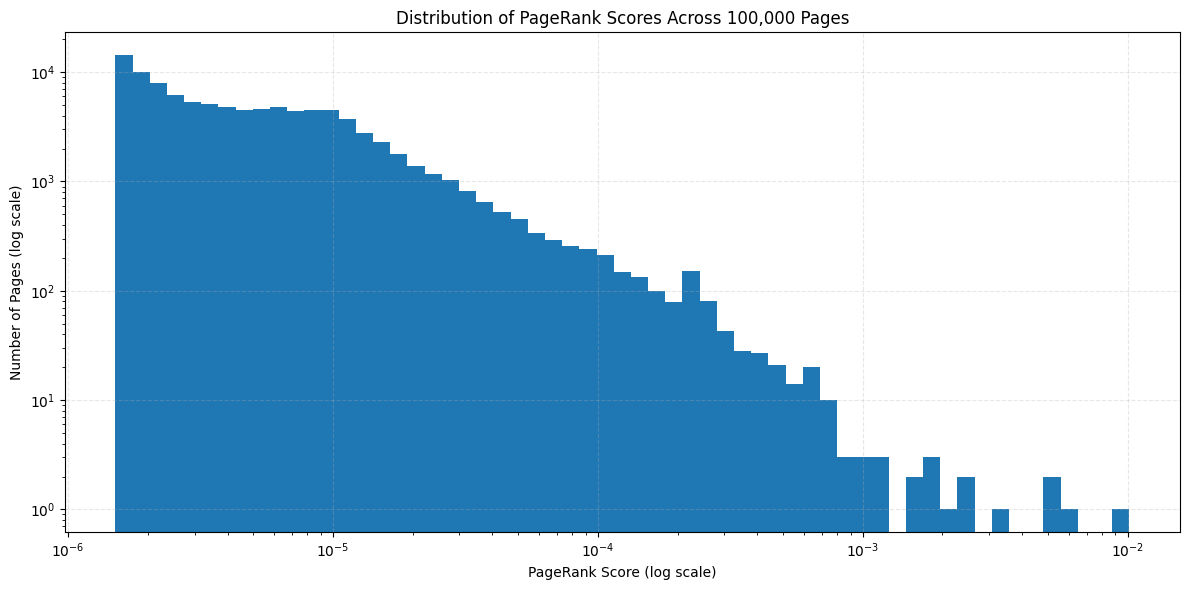

In [ ]:

#Analyze and visualize PageRank score distribution

import numpy as np

scores = np.array(list(pagerank_scores.values()))

print("PageRank score distribution")
print("----------------------------")
print("Minimum:", f"{scores.min():.10f}")
print("Median:", f"{np.median(scores):.10f}")
print("Mean:", f"{scores.mean():.10f}")
print("Maximum:", f"{scores.max():.10f}")
print("Standard deviation:", f"{scores.std():.10f}")


# Improved PageRank score distribution plot

scores = np.array(list(pagerank_scores.values()))

# Create bins evenly spaced in log space
log_bins = np.logspace(
    np.log10(scores.min()),
    np.log10(scores.max()),
    60
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(scores, bins=log_bins)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("PageRank Score (log scale)")
ax.set_ylabel("Number of Pages (log scale)")
ax.set_title("Distribution of PageRank Scores Across 100,000 Pages")
ax.grid(axis="both", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig(
    results_dir / "pagerank_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


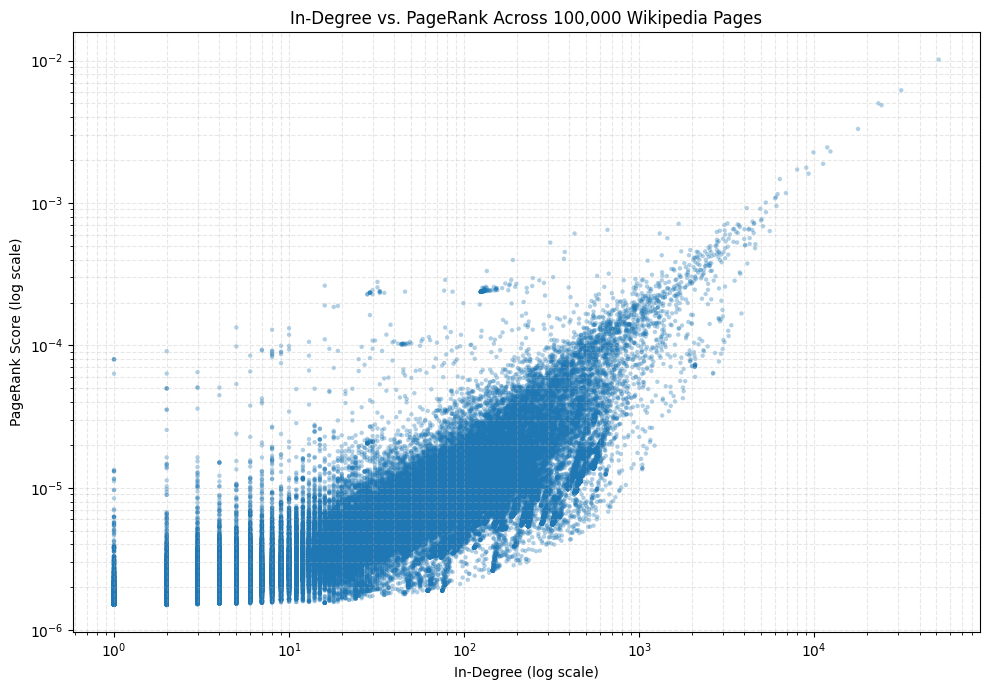

Scatter plot saved to: /content/graph_analysis_results/indegree_vs_pagerank_scatter.png


In [ ]:

#Compare in-degree and PageRank visually

import numpy as np

# Ensure both dictionaries use the same graph nodes
nodes = list(pagerank_scores.keys())

degree_values = np.array([
    in_degrees[node] for node in nodes
])

pr_values = np.array([
    pagerank_scores[node] for node in nodes
])

fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    degree_values,
    pr_values,
    alpha=0.35,
    s=10,
    edgecolors="none"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("In-Degree (log scale)")
ax.set_ylabel("PageRank Score (log scale)")
ax.set_title("In-Degree vs. PageRank Across 100,000 Wikipedia Pages")

ax.grid(True, which="both", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig(
    results_dir / "indegree_vs_pagerank_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Scatter plot saved to:",
    results_dir / "indegree_vs_pagerank_scatter.png"
)


In [ ]:

# Consolidate final results and verify saved files

import json
from pathlib import Path

# 1. Check required variables
required_variables = [
    "G_100k",
    "pagerank_scores",
    "pagerank_ranking",
    "top_10_pagerank",
    "comparison",
    "overlap",
    "elapsed_time",
    "damping_factor",
    "tolerance",
    "max_iterations",
    "graph_summary",
    "results_dir"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise NameError(
        f"Missing variables: {missing}. "
        "Run the corresponding earlier cells first."
    )

results_dir = Path(results_dir)
results_dir.mkdir(parents=True, exist_ok=True)

# 2. Calculate summary statistics from existing results
scores = list(pagerank_scores.values())

from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    comparison["in_degree"],
    comparison["pagerank_score"]
)

# 3. Create a reproducibility summary
experiment_summary = {
    "project": "Wikipedia PageRank Analysis",
    "dataset_pages": G_100k.number_of_nodes(),
    "directed_edges": G_100k.number_of_edges(),
    "self_loops": int(nx.number_of_selfloops(G_100k)),
    "pagerank_parameters": {
        "damping_factor": damping_factor,
        "tolerance": tolerance,
        "maximum_iterations": max_iterations,
        "execution_time_seconds": round(elapsed_time, 2),
        "number_of_pages_ranked": len(pagerank_scores),
        "sum_of_pagerank_scores": float(sum(scores))
    },
    "pagerank_distribution": {
        "minimum": float(min(scores)),
        "median": float(pd.Series(scores).median()),
        "mean": float(pd.Series(scores).mean()),
        "maximum": float(max(scores)),
        "standard_deviation": float(pd.Series(scores).std(ddof=0))
    },
    "ranking_comparison": {
        "pages_matched": len(comparison),
        "top_10_overlap_count": len(overlap),
        "top_10_overlap_pages": sorted(list(overlap)),
        "spearman_correlation": float(correlation),
        "spearman_p_value": float(p_value)
    }
}

summary_path = results_dir / "final_experiment_summary.json"

with open(summary_path, "w") as f:
    json.dump(experiment_summary, f, indent=4)

# 4. Verify expected result files
expected_files = [
    "top_10_in_degree.csv",
    "graph_summary.json",
    "pagerank_ranking_100k.csv",
    "top_10_pagerank.csv",
    "indegree_pagerank_comparison_100k.csv",
    "top10_ranking_comparison.csv",
    "top_10_pagerank.png",
    "pagerank_score_distribution.png",
    "indegree_vs_pagerank_scatter.png",
    "final_experiment_summary.json"
]

print("FINAL RESULTS VERIFICATION")
print("=" * 45)

for filename in expected_files:
    path = results_dir / filename
    status = "FOUND" if path.is_file() else "MISSING"
    print(f"{status:8} | {filename}")

print("\nExperiment summary:")
print(json.dumps(experiment_summary, indent=2))

print("\nResults folder:", results_dir)


FINAL RESULTS VERIFICATION
FOUND    | top_10_in_degree.csv
FOUND    | graph_summary.json
FOUND    | pagerank_ranking_100k.csv
FOUND    | top_10_pagerank.csv
FOUND    | indegree_pagerank_comparison_100k.csv
FOUND    | top10_ranking_comparison.csv
FOUND    | top_10_pagerank.png
FOUND    | pagerank_score_distribution.png
FOUND    | indegree_vs_pagerank_scatter.png
FOUND    | final_experiment_summary.json

Experiment summary:
{
  "project": "Wikipedia PageRank Analysis",
  "dataset_pages": 100000,
  "directed_edges": 8577044,
  "self_loops": 4326,
  "pagerank_parameters": {
    "damping_factor": 0.85,
    "tolerance": 1e-06,
    "maximum_iterations": 100,
    "execution_time_seconds": 21.18,
    "number_of_pages_ranked": 100000,
    "sum_of_pagerank_scores": 0.9999999999999997
  },
  "pagerank_distribution": {
    "minimum": 1.5073374942792037e-06,
    "median": 3.804682645439931e-06,
    "mean": 9.999999999999994e-06,
    "maximum": 0.01015125124917978,
    "standard_deviation": 5.5491804

In [ ]:

# Final backup: package all analysis results into one ZIP

import shutil
from pathlib import Path

results_dir = Path("/content/graph_analysis_results")
backup_path = shutil.make_archive(
    "/content/wikipedia_pagerank_final_results",
    "zip",
    root_dir=results_dir
)

print("Backup created:", backup_path)


Backup created: /content/wikipedia_pagerank_final_results.zip
Download it from the Colab Files panel.
